In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, f_oneway

# Задача 1. Платформа найма и ранжирование вакансий

Вы работаете аналитиком в агрегаторе найма (по аналогии с hh.ru).

Ваша первичная задача — увеличить **среднее количество откликов** от соискателя на вакансии за месяц.

Коллеги из бэкенд-разработки придумали два альтернативных решения по выдаче топ-вакансий для соискателей.
 - Воздействия А1 и А2 — это текущая механика, *контрольная группа*.

 Подразумевает выдачу по текущему алгоритму.

 Разделение произведено для оценки качества сплит-системы.

 - Воздействие В — «Воздействие тест 1»: подразумевает ранжирование вакансий с учётом большего количества признаков пользователя.
 - Воздействие С — «Воздействие тест 2»: подразумевает ранжирование вакансий с помощью искусственного интеллекта.


Рассчитайте результаты множественного теста (файл *hh_aabc_test.xlsx*) и сделайте вывод:
- о качестве сплит-системы (на основании A1 vs A2);
- воздействии тестовых механик В и С.

Рассчитайте значение F-теста для групповой и межгрупповой дисперсии — как соотносятся выводы F-теста с выводами множественного t-теста?

In [ ]:
dfm = pd.read_excel("hh_aabc_test.xlsx")

dfm.head()

,id_client,id_group,cnt_answer
0,10033545,A2,4
1,10032936,B,78
2,10036491,A2,92
3,10032200,A2,81
4,10035924,C,90


In [ ]:
dfm['id_group'].unique()

array(['A2', 'B', 'C', 'A1'], dtype=object)

У нас в данном случае 4 различных группы, и нашим окончательным решением по тесту будет сложносоставной вывод, основанный на нескольких попарных сравнениях.

В связи с этим необходимо применить правила **множественной поправки**.

## Метод Бонферрони



Пусть $n$ — количество попарных сравнений в рамках множественного теста.

Определим новую ошибку первого рода для каждого попарного тестирования как отношение ошибки первого рода для множественного тестирования к количеству тестов.

$$\alpha_{pair}=\frac{\alpha_{FWE}}{n},$$

где $\alpha_{FWE}$ — *Family-wise Error*.

Теперь проведём каждое попарное сравнение с учётом поправки

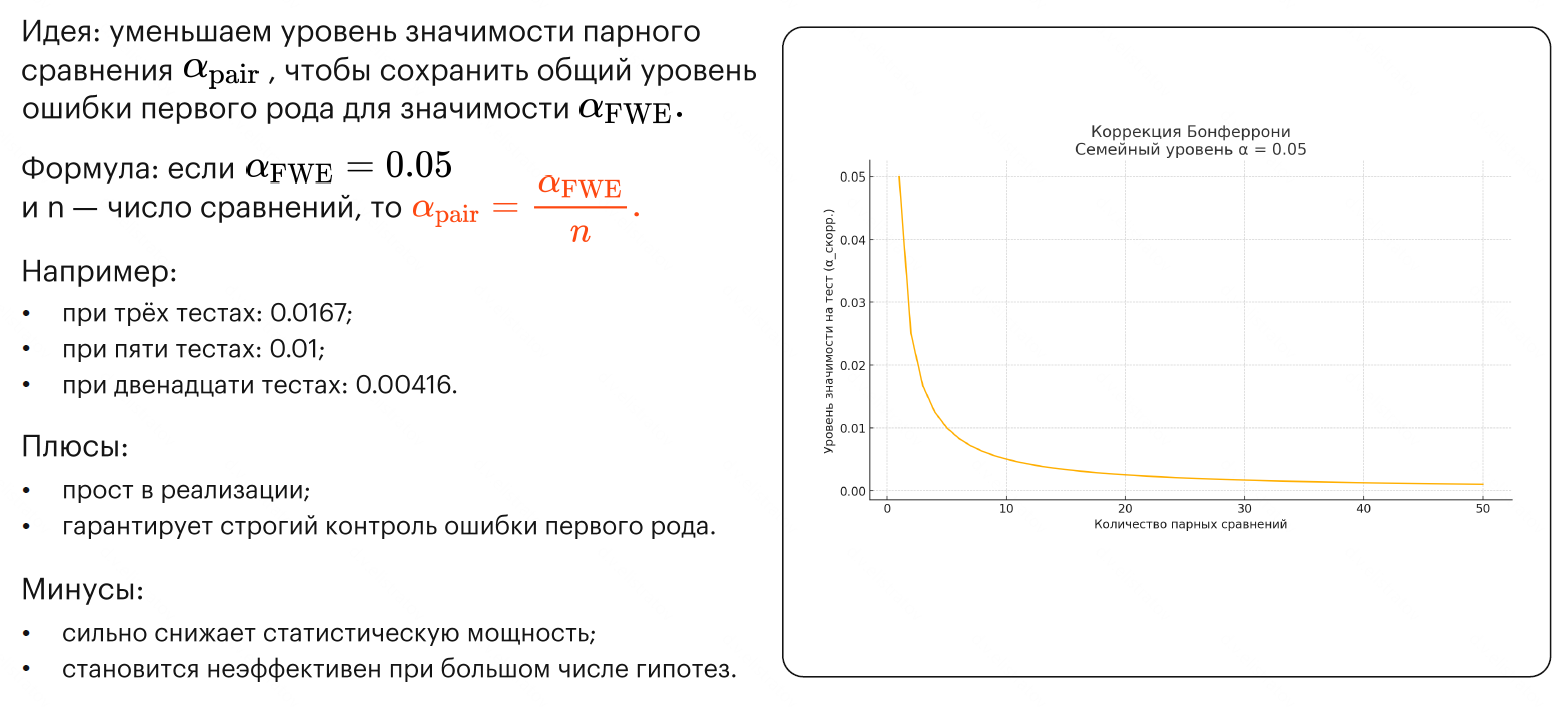

In [ ]:
groups = sorted(dfm['id_group'].unique())

Выведем средние в группах

In [ ]:
for i in groups:
  mean = dfm[dfm['id_group']==i]['cnt_answer'].mean()
  print(f'{i}: Среднее кол-во откликов – {round(mean, 2)}')

A1: Среднее кол-во откликов – 68.05
A2: Среднее кол-во откликов – 69.3
B: Среднее кол-во откликов – 78.49
C: Среднее кол-во откликов – 66.81


Для каждой комбинации групп рассчитаем результаты теста

In [ ]:
res_dict = {}

for i in groups:
  for j in groups:
    if i != j:
      semp_i = dfm[dfm['id_group']==i]['cnt_answer'].values
      semp_j = dfm[dfm['id_group']==j]['cnt_answer'].values
      mean_i, mean_j = np.mean(semp_i), np.mean(semp_j)
      _, p_value = ttest_ind(semp_i, semp_j)
      res_dict[f'{i}_vs_{j}'] = [round(mean_j - mean_i, 1), p_value]



df_piar = pd.DataFrame(res_dict).T.reset_index()
df_piar.columns = ['pair', 'uplift', 'p_value']

print(f'Число сравнений: {len(df_piar)}')

df_piar

Число сравнений: 12


,pair,uplift,p_value
0,A1_vs_A2,1.3,2.464929e-01
1,A1_vs_B,10.4,1.592826e-20
2,A1_vs_C,-1.2,2.752736e-01
3,A2_vs_A1,-1.3,2.464929e-01
4,A2_vs_B,9.2,1.010565e-16
5,A2_vs_C,-2.5,2.630041e-02
6,B_vs_A1,-10.4,1.592826e-20
7,B_vs_A2,-9.2,1.010565e-16
8,B_vs_C,-11.7,1.420667e-23
9,C_vs_A1,1.2,2.752736e-01


Оставим только разные комбинации с точки зрения сочетаний

In [ ]:
df_piar_uniq = df_piar[df_piar.pair.isin(['A1_vs_A2','A1_vs_B','A2_vs_B','A1_vs_C','A2_vs_C','B_vs_C'])]

print(f'Число уникальных сравнений: {len(df_piar_uniq)}')

df_piar_uniq

Число уникальных сравнений: 6


,pair,uplift,p_value
0,A1_vs_A2,1.3,2.464929e-01
1,A1_vs_B,10.4,1.592826e-20
2,A1_vs_C,-1.2,2.752736e-01
4,A2_vs_B,9.2,1.010565e-16
5,A2_vs_C,-2.5,2.630041e-02
8,B_vs_C,-11.7,1.420667e-23


Рассчитаем альфу с поправкой Бонферрони

In [ ]:
alpha = 0.05

alpha_bnfr = alpha / len(df_piar_uniq)

alpha_bnfr

0.008333333333333333

Внесём значения $\alpha$ и $\alpha_B$ в датафрейм.

In [ ]:
df_piar_uniq.loc[:, 'alpha'] = alpha
df_piar_uniq.loc[:, 'alpha_bnfr'] = alpha_bnfr

/tmp/ipykernel_6544/470836575.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_piar_uniq.loc[:, 'alpha'] = alpha
/tmp/ipykernel_6544/470836575.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_piar_uniq.loc[:, 'alpha_bnfr'] = alpha_bnfr


In [ ]:
df_piar_uniq

,pair,uplift,p_value,alpha,alpha_bnfr
0,A1_vs_A2,1.3,2.464929e-01,0.05,0.008333
1,A1_vs_B,10.4,1.592826e-20,0.05,0.008333
2,A1_vs_C,-1.2,2.752736e-01,0.05,0.008333
4,A2_vs_B,9.2,1.010565e-16,0.05,0.008333
5,A2_vs_C,-2.5,2.630041e-02,0.05,0.008333
8,B_vs_C,-11.7,1.420667e-23,0.05,0.008333


Выведем список тестов, которые прокрасятся с обычной альфой.

In [ ]:
df_piar_uniq[df_piar_uniq.p_value < df_piar_uniq.alpha]

,pair,uplift,p_value,alpha,alpha_bnfr
1,A1_vs_B,10.4,1.592826e-20,0.05,0.008333
4,A2_vs_B,9.2,1.010565e-16,0.05,0.008333
5,A2_vs_C,-2.5,2.630041e-02,0.05,0.008333
8,B_vs_C,-11.7,1.420667e-23,0.05,0.008333


Выведем список тестов, которые прокрасятся с альфой Бонферрони.

In [ ]:
df_piar_uniq[df_piar_uniq.p_value < df_piar_uniq.alpha_bnfr]

,pair,uplift,p_value,alpha,alpha_bnfr
1,A1_vs_B,10.4,1.592826e-20,0.05,0.008333
4,A2_vs_B,9.2,1.010565e-16,0.05,0.008333
8,B_vs_C,-11.7,1.420667e-23,0.05,0.008333


**Вывод**

Без поправки Бонферонни мы могли бы сделать вывод о том, что механика с использованием ИИ проигрывает группе А2, т.е. эта механика не то что не улучшила, а даже ухудшила изначальный флоу.

Однако после поправки Бонфронни мы делаем вывод о том, что статистически значимой разницы между контрольными группами и механикой С нет.

## Метод Холма

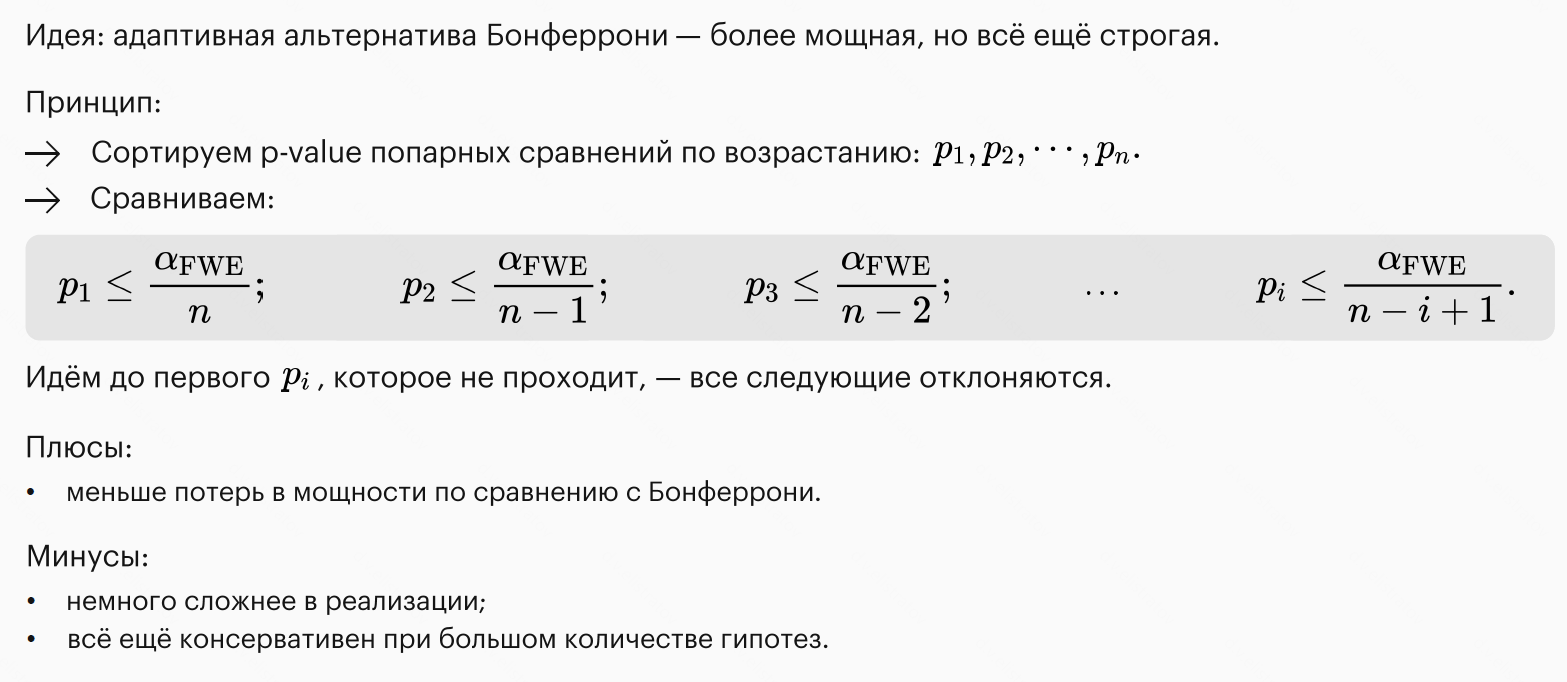

In [ ]:
holm_alphas = []
n_comparison = len(df_piar_uniq)

for i in range(n_comparison):
  alpha_i = alpha / (n_comparison-i)
  holm_alphas.append(alpha_i)
  print(f"Альфа номер {i+1}: {round(100*alpha_i, 2)}%")

Альфа номер 1: 0.83%
Альфа номер 2: 1.0%
Альфа номер 3: 1.25%
Альфа номер 4: 1.67%
Альфа номер 5: 2.5%
Альфа номер 6: 5.0%


In [ ]:
## Сортируем по возрастанию значений p-value
df_piar_uniq = df_piar_uniq.sort_values(by='p_value').reset_index(drop=True).copy()
df_piar_uniq

,pair,uplift,p_value,alpha,alpha_bnfr
0,B_vs_C,-11.7,1.420667e-23,0.05,0.008333
1,A1_vs_B,10.4,1.592826e-20,0.05,0.008333
2,A2_vs_B,9.2,1.010565e-16,0.05,0.008333
3,A2_vs_C,-2.5,2.630041e-02,0.05,0.008333
4,A1_vs_A2,1.3,2.464929e-01,0.05,0.008333
5,A1_vs_C,-1.2,2.752736e-01,0.05,0.008333


In [ ]:
alphas = pd.Series(holm_alphas, name='alpha_hlm')

df_piar_uniq.loc[:, 'alpha_hlm'] = alphas

In [ ]:
df_piar_uniq

,pair,uplift,p_value,alpha,alpha_bnfr,alpha_hlm
0,B_vs_C,-11.7,1.420667e-23,0.05,0.008333,0.008333
1,A1_vs_B,10.4,1.592826e-20,0.05,0.008333,0.010000
2,A2_vs_B,9.2,1.010565e-16,0.05,0.008333,0.012500
3,A2_vs_C,-2.5,2.630041e-02,0.05,0.008333,0.016667
4,A1_vs_A2,1.3,2.464929e-01,0.05,0.008333,0.025000
5,A1_vs_C,-1.2,2.752736e-01,0.05,0.008333,0.050000


Выведем список тестов, которые прокрасятся с альфой Холма.

Однако надо учесть, что мы доходим до первого непрокраса и останавливаемся!

In [ ]:
df_piar_uniq[df_piar_uniq.p_value < df_piar_uniq.alpha_hlm]

,pair,uplift,p_value,alpha,alpha_bnfr,alpha_hlm
0,B_vs_C,-11.7,1.420667e-23,0.05,0.008333,0.008333
1,A1_vs_B,10.4,1.592826e-20,0.05,0.008333,0.010000
2,A2_vs_B,9.2,1.010565e-16,0.05,0.008333,0.012500


## F-тест



Покажет ли F-тест наличие прокрасов на общей выборке групп?

In [ ]:
dfm.head()

,id_client,id_group,cnt_answer
0,10033545,A2,4
1,10032936,B,78
2,10036491,A2,92
3,10032200,A2,81
4,10035924,C,90


Рассчитаем внутригрупповую дисперсию

In [ ]:
var_within = 0

for i in dfm['id_group'].unique():
  sum_ = 0
  df_loc = dfm[dfm['id_group']==i]

  m = df_loc['cnt_answer'].mean()

  sum_ += ((df_loc['cnt_answer'] - m)**2).sum()
  var_within += sum_

print("Внутригрупповая дисперсия составляет ", round(var_within))

Внутригрупповая дисперсия составляет  10465519


Рассчитаем межгрупповую дисперсию

In [ ]:
global_m = dfm['cnt_answer'].mean()

var_between = 0

for i in dfm['id_group'].unique():

  m = dfm[dfm['id_group']==i]['cnt_answer'].mean()

  var_between += ((m - global_m)**2) * len(dfm[dfm['id_group']==i])

print("Межгрупповая дисперсия составляет ", round(var_between))

Межгрупповая дисперсия составляет  173501


Рассчитаем кол-во степеней свободы межгрупповой и внутригрупповой дисперсии.

In [ ]:
k = len(dfm['id_group'].unique())
N = len(dfm)

df_between = k - 1
df_within = N - k

print("Всего ", N, " наблюдений")
print("Всего ", k, " группы")

print("Кол-во степеней свободы битвин", df_between)
print("Кол-во степеней свободы визин", df_within)

Всего  8177  наблюдений
Всего  4  группы
Кол-во степеней свободы битвин 3
Кол-во степеней свободы визин 8173


Рассчитаем F-значение.

In [ ]:
from scipy.stats import f

In [ ]:
print("Нормированная межгрупповая дисперсия = ", var_between / df_between)
print("Нормированная внутригрупповая дисперсия = ", var_within / df_within)

F_val = (var_between / df_between) / (var_within / df_within)
f_critical = f.ppf(1 - .05, df_between, df_within)

print("Расчётное F-значение = ", F_val)
print("Критическое F-значение = ", f_critical)

Нормированная межгрупповая дисперсия =  57833.82120182884
Нормированная внутригрупповая дисперсия =  1280.4990913685797
Расчётное F-значение =  45.16506227272434
Критическое F-значение =  2.605995575771456


In [ ]:
print(f.cdf(F_val, df_between, df_within))
print(1 - f.cdf(F_val, df_between, df_within))

0.9999999999999999
1.1102230246251565e-16


P-value маленькое, а значит, гипотеза об отсутствии прокрасов отвергается.

Это говорит нам о том, что хоть какая-то разница (прокрасы) между группами есть и имеет смысл углубляться в попарные сравнения.

**Рассмотрим отдельно непрокрасившиеся группы.**

In [ ]:
df3 = dfm[dfm['id_group'].isin(['A1','A2','C'])]

global_m_3 = df3['cnt_answer'].mean()

var_within_3 = 0
var_between_3 = 0

df_between_3 = len(df3['id_group'].unique()) - 1
df_within_3 = len(df3) - len(df3['id_group'].unique())

###########################################

for i in df3['id_group'].unique():
  sum_ = 0
  df_loc = df3[df3['id_group']==i]
  m = df_loc['cnt_answer'].mean()
  sum_ += ((df_loc['cnt_answer'] - m)**2).sum()
  var_within_3 += sum_

###########################################

for i in df3['id_group'].unique():
  m = df3[df3['id_group']==i]['cnt_answer'].mean()
  var_between_3 += ((m - global_m_3)**2) * len(df3[df3['id_group']==i])

###########################################

F_val_3 = (var_between_3 / df_between_3) / (var_within_3 / df_within_3)
f_critical_3 = f.ppf(1 - .05, df_between_3, df_within_3)

print("Нормированная межгрупповая дисперсия = ", var_between_3 / df_between_3)
print("Нормированная внутригрупповая дисперсия = ", var_within_3 / df_within_3)
print("Расчётное F-значение = ", F_val_3)
print("Критическое F-значение = ", f_critical_3)
print("p-value = ", 1 - f.cdf(F_val_3, df_between_3, df_within_3))

Нормированная межгрупповая дисперсия =  3150.650691747112
Нормированная внутригрупповая дисперсия =  1261.5383267084171
Расчётное F-значение =  2.497467278673754
Критическое F-значение =  2.99719963906236
p-value =  0.08237705608544821


P-value больше альфы, а значит, нулевая гипотеза об отсутствии прокрасов в рамках этих трёх групп отвергается.

Однако значение p-value незначительно превосходит $5\%$, что объясняется «почти прокрасившейся» разницей между А2 и С.

**Рассмотрим отдельно АА-тест.**

In [ ]:
df2 = dfm[dfm['id_group'].isin(['A1','A2'])]

global_m_2 = df2['cnt_answer'].mean()

var_within_2 = 0
var_between_2 = 0

df_between_2 = len(df2['id_group'].unique()) - 1
df_within_2 = len(df2) - len(df2['id_group'].unique())

###########################################

for i in df2['id_group'].unique():
  sum_ = 0
  df_loc = df2[df2['id_group']==i]
  m = df_loc['cnt_answer'].mean()
  sum_ += ((df_loc['cnt_answer'] - m)**2).sum()
  var_within_2 += sum_

###########################################

for i in df2['id_group'].unique():
  m = df2[df2['id_group']==i]['cnt_answer'].mean()
  var_between_2 += ((m - global_m_2)**2) * len(df2[df2['id_group']==i])

###########################################

F_val_2 = (var_between_2 / df_between_2) / (var_within_2 / df_within_2)
f_critical_2 = f.ppf(1 - .05, df_between_2, df_within_2)

print("Нормированная межгрупповая дисперсия = ", var_between_2 / df_between_2)
print("Нормированная внутригрупповая дисперсия = ", var_within_2 / df_within_2)
print("Расчётное F-значение = ", F_val_2)
print("Критическое F-значение = ", f_critical_2)
print("p-value = ", 1 - f.cdf(F_val_2, df_between_2, df_within_2))

Нормированная межгрупповая дисперсия =  1608.4547402345936
Нормированная внутригрупповая дисперсия =  1197.252599604606
Расчётное F-значение =  1.343454790380733
Критическое F-значение =  3.8437196202122865
p-value =  0.2464928813967101


In [ ]:
res = ttest_ind(dfm[dfm.id_group=='A2'].cnt_answer.values, dfm[dfm.id_group=='A1'].cnt_answer.values)

f'p-value: {res.pvalue}'

'p-value: 0.2464928813956843'

В этот раз p-value значительно больше альфы, что объясняется отсутствием ощутимой разницы между группами А1 и А2.

**Замечание!** На практике так не проверяют работу сплит-системы, потому что группы А1 и А2 могут прокрашиваться рандомно, так как это буквально суть статистической проверки гипотез.

**Поменяем выборку.**

Как поменяются результаты anova F-теста?

Искусственно сделаем группу С резко отличающейся от остальных и проверим поведение расчётной F-статистики.

In [ ]:
df3_copy = df3.copy()

df3_copy.loc[df3_copy['id_group']=='C', 'cnt_answer'] += 60
global_m_3 = df3_copy['cnt_answer'].mean()

var_within_3 = 0
var_between_3 = 0

df_between_3 = len(df3_copy['id_group'].unique()) - 1
df_within_3 = len(df3_copy) - len(df3_copy['id_group'].unique())

###########################################

for i in df3_copy['id_group'].unique():
  sum_ = 0
  df_loc = df3_copy[df3_copy['id_group']==i]
  m = df_loc['cnt_answer'].mean()
  sum_ += ((df_loc['cnt_answer'] - m)**2).sum()
  var_within_3 += sum_

###########################################

for i in df3_copy['id_group'].unique():
  m = df3_copy[df3_copy['id_group']==i]['cnt_answer'].mean()
  var_between_3 += ((m - global_m)**2) * len(df3_copy[df3_copy['id_group']==i])

###########################################

F_val_3 = (var_between_3 / df_between_3) / (var_within_3 / df_within_3)
f_critical_3 = f.ppf(1 - .05, df_between_3, df_within_3)

print("Нормированная межгрупповая дисперсия = ", var_between_3 / df_between_3)
print("Нормированная внутригрупповая дисперсия = ", var_within_3 / df_within_3)
print("Расчётное F-значение = ", F_val_3)
print("Критическое F-значение = ", f_critical_3)
print("p-value = ", 1 - f.cdf(F_val_3, df_between_3, df_within_3))

Нормированная межгрупповая дисперсия =  3165351.7546130153
Нормированная внутригрупповая дисперсия =  1261.5383267084171
Расчётное F-значение =  2509.120561459273
Критическое F-значение =  2.99719963906236
p-value =  1.1102230246251565e-16


**Вывод**

Результаты F-теста совпадают с результатами потенциальных попарных сравнений.

# Задача 2. P-hacking. Вариант 1

In [ ]:
df_ph = pd.read_excel('phacking_data_1.xlsx')

df_ph.head()

,id_client,date_pay,id_group,amt_pay
0,18427,2024-02-01,test,1868
1,18590,2024-02-01,control,3620
2,21611,2024-02-01,control,3478
3,25086,2024-02-01,test,1020
4,26218,2024-02-01,test,2104


In [ ]:
s, p = ttest_ind(df_ph[df_ph['id_group']=='control']['amt_pay'], df_ph[df_ph['id_group']=='test']['amt_pay'])

print(s)
print(p)

-2.1704941592608322
0.030006372951461732


In [ ]:
df_ph_gr = df_ph.groupby(['id_group', 'date_pay'], as_index=False).agg(
    avg_pay=('amt_pay','mean'),
    cnt=('id_client', 'count'),
    var=('amt_pay', 'var')
)

df_ph_gr.head()

,id_group,date_pay,avg_pay,cnt,var
0,control,2024-02-01,3490.000000,27,1.486177e+06
1,control,2024-02-02,3413.354839,31,2.501712e+06
2,control,2024-02-03,3019.875000,24,2.647086e+06
3,control,2024-02-04,2466.750000,28,1.267537e+06
4,control,2024-02-05,2682.629630,27,2.460652e+06


## Визуализация динамики средних в двух группах

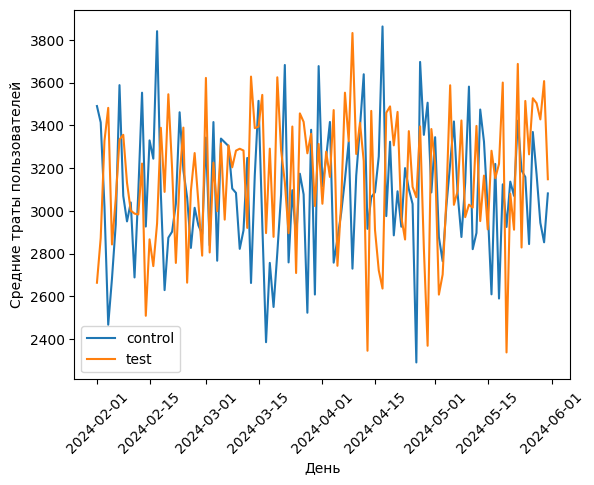

In [ ]:
contr_cond = df_ph_gr['id_group']=='control'

plt.plot(df_ph_gr[contr_cond]['date_pay'], df_ph_gr[contr_cond]['avg_pay'], label='control')
plt.plot(df_ph_gr[~contr_cond]['date_pay'], df_ph_gr[~contr_cond]['avg_pay'], label='test')
plt.ylabel('Средние траты пользователей')
plt.xlabel('День')
plt.legend(loc='lower left')
plt.xticks(rotation=45)
plt.show()

## Визуализация стат. критерия для каждого дня

In [ ]:
df_loc_control = df_ph_gr[contr_cond][['date_pay', 'avg_pay', 'cnt', 'var']]
df_loc_test = df_ph_gr[~contr_cond][['date_pay', 'avg_pay', 'cnt', 'var']]

df_4stat = df_loc_test.merge(df_loc_control, on='date_pay', suffixes=('_t', '_c'))

df_4stat.head()

,date_pay,avg_pay_t,cnt_t,var_t,avg_pay_c,cnt_c,var_c
0,2024-02-01,2663.441176,34,1.761379e+06,3490.000000,27,1.486177e+06
1,2024-02-02,2872.812500,16,2.875629e+06,3413.354839,31,2.501712e+06
2,2024-02-03,3327.333333,27,1.970887e+06,3019.875000,24,2.647086e+06
3,2024-02-04,3481.545455,22,2.518541e+06,2466.750000,28,1.267537e+06
4,2024-02-05,2842.400000,20,1.861202e+06,2682.629630,27,2.460652e+06


In [ ]:
df_4stat['z_cr'] = (
    (df_4stat['avg_pay_t'] - df_4stat['avg_pay_c'])
      / (df_4stat['var_t']/df_4stat['cnt_t'] + df_4stat['var_c']/df_4stat['cnt_c'])**.5
)

df_4stat.head()

,date_pay,avg_pay_t,cnt_t,var_t,avg_pay_c,cnt_c,var_c,z_cr
0,2024-02-01,2663.441176,34,1.761379e+06,3490.000000,27,1.486177e+06,-2.528651
1,2024-02-02,2872.812500,16,2.875629e+06,3413.354839,31,2.501712e+06,-1.059221
2,2024-02-03,3327.333333,27,1.970887e+06,3019.875000,24,2.647086e+06,0.718151
3,2024-02-04,3481.545455,22,2.518541e+06,2466.750000,28,1.267537e+06,2.538987
4,2024-02-05,2842.400000,20,1.861202e+06,2682.629630,27,2.460652e+06,0.372269


67.26157466968455


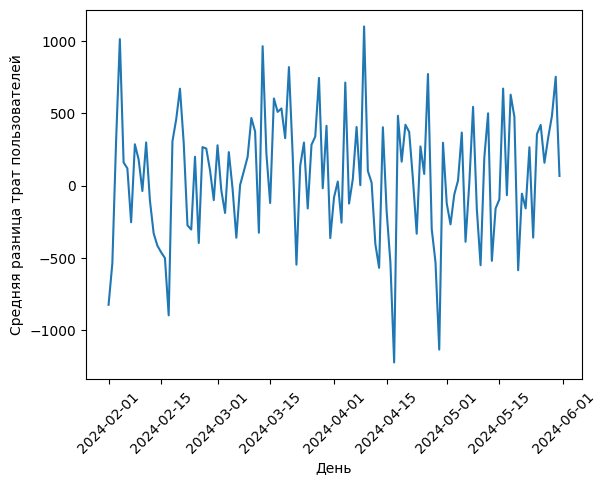

In [ ]:
print((df_4stat['avg_pay_t'] - df_4stat['avg_pay_c']).mean())

plt.plot(df_4stat['date_pay'], df_4stat['avg_pay_t']-df_4stat['avg_pay_c'])
plt.ylabel('Средняя разница трат пользователей')
plt.xlabel('День')
plt.xticks(rotation = 45)
plt.show()

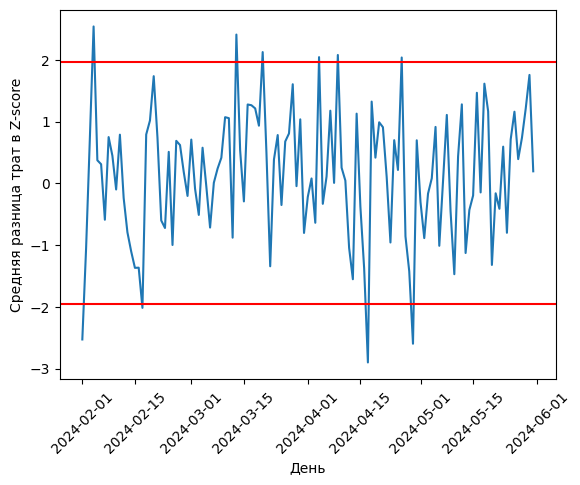

In [ ]:
plt.plot(df_4stat['date_pay'] , df_4stat['z_cr'])
plt.axhline(1.96, color = 'red')
plt.axhline(-1.96, color = 'red')
plt.ylabel('Средняя разница трат в Z-score')
plt.xlabel('День')
plt.xticks(rotation = 45)
plt.show()

## Визуализация стат. критерия для каждого дня (кумулятивное значение)

In [ ]:
df_ph.head()

,id_client,date_pay,id_group,amt_pay
0,18427,2024-02-01,test,1868
1,18590,2024-02-01,control,3620
2,21611,2024-02-01,control,3478
3,25086,2024-02-01,test,1020
4,26218,2024-02-01,test,2104


In [ ]:
df_fin = pd.DataFrame()

for i in df_ph['date_pay'].unique():
  df_loc = df_ph[df_ph['date_pay'] <= i]

  mean_ctrl = df_loc[df_loc['id_group']=='control']['amt_pay'].mean()
  mean_test = df_loc[df_loc['id_group']=='test']['amt_pay'].mean()

  s, p = ttest_ind(df_loc[df_loc['id_group']=='control']['amt_pay'], df_loc[df_loc['id_group']=='test']['amt_pay'])

  df_fin_loc = pd.DataFrame({'date':i, 'm_ctrl':mean_ctrl, 'm_test':mean_test, 's':s, 'p':p}, index=[0])

  df_fin = pd.concat([df_fin, df_fin_loc])

df_fin.head(15)

,date,m_ctrl,m_test,s,p
0,2024-02-01,3490.000000,2663.441176,2.503771,0.015074
0,2024-02-02,3449.034483,2730.440000,2.611479,0.010322
0,2024-02-03,3323.426829,2939.740260,1.650278,0.100885
0,2024-02-04,3105.363636,3060.141414,0.222771,0.823934
0,2024-02-05,3022.051095,3023.546218,-0.008120,0.993528
0,2024-02-06,3008.349693,3030.080000,-0.131462,0.895495
0,2024-02-07,3077.270270,3074.863636,0.015585,0.987574
0,2024-02-08,3076.218605,3107.296482,-0.217135,0.828211
0,2024-02-09,3064.046218,3110.562771,-0.345263,0.730052
0,2024-02-10,3061.490566,3097.587786,-0.285134,0.775654


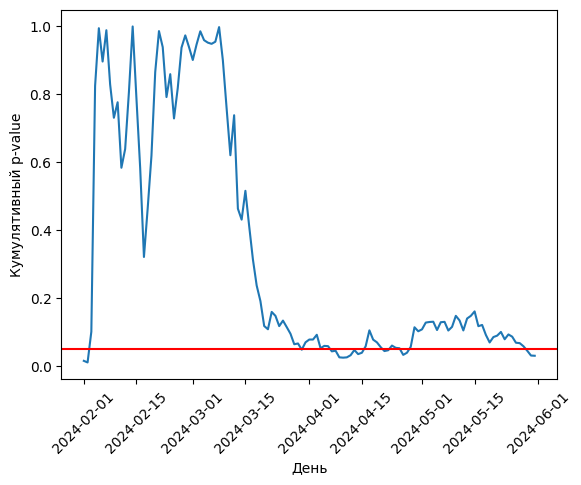

In [ ]:
plt.plot(df_fin['date'] , df_fin['p'])
plt.axhline(.05, color = 'red')
plt.ylabel('Кумулятивный p-value')
plt.xlabel('День')
plt.xticks(rotation = 45)
plt.show()

**Вывод**

Нельзя подсматривать, так как прокрас может появиться не сразу.

# Задача 3. P-hacking. Вариант 2

In [ ]:
df_ph2 = pd.read_excel('phacking_data_2.xlsx')

df_ph2.head()

,sl,id_oper,day,id_group,flag_res
0,0.337539,100901,1,control,0
1,0.029684,100902,1,test,1
2,0.997207,100903,1,test,0
3,0.687731,100904,1,control,0
4,0.789734,100905,1,control,1


In [ ]:
contr_cond = df_ph2['id_group']=='control'
s, p = ttest_ind(df_ph2[contr_cond]['flag_res'], df_ph2[~contr_cond]['flag_res'])

print(s)
print(p)

-1.26529162225106
0.2058002341911164


In [ ]:
df_ph_gr2 = df_ph2.groupby(['id_group', 'day'], as_index=False).agg(
    avg_res=('flag_res','mean'),
    cnt=('id_oper', 'count')
)

df_ph_gr2.head()

,id_group,day,avg_res,cnt
0,control,1,0.392377,446
1,control,2,0.405467,439
2,control,3,0.413502,474
3,control,4,0.437500,448
4,control,5,0.396679,542


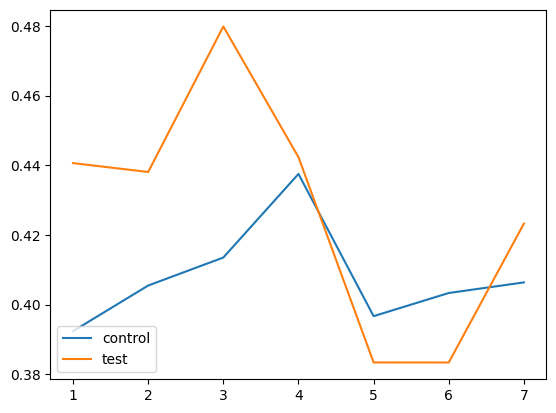

In [ ]:
plt.plot(df_ph_gr2[df_ph_gr2['id_group']=='control']['day'] , df_ph_gr2[df_ph_gr2['id_group']=='control']['avg_res'], label = 'control')
plt.plot(df_ph_gr2[df_ph_gr2['id_group']=='test']['day']    , df_ph_gr2[df_ph_gr2['id_group']=='test']['avg_res']   , label = 'test'   )
plt.legend(loc = 'lower left')
plt.show()

In [ ]:
df_fin2 = pd.DataFrame()

for i in df_ph2['day'].unique():
  df_loc = df_ph2[df_ph2['day'] <= i]

  mean_ctrl = df_loc[df_loc['id_group']=='control']['flag_res'].mean()
  mean_test = df_loc[df_loc['id_group']=='test']['flag_res'].mean()

  s, p = ttest_ind(df_loc[df_loc['id_group']=='control']['flag_res'], df_loc[df_loc['id_group']=='test']['flag_res'])

  df_fin_loc = pd.DataFrame({'date':i, 'm_ctrl':mean_ctrl, 'm_test':mean_test, 's':s, 'p':p}, index=[0])

  df_fin2 = pd.concat([df_fin2, df_fin_loc])

df_fin2.head(15)

,date,m_ctrl,m_test,s,p
0,1,0.392377,0.440605,-1.474429,0.140713
0,2,0.398870,0.439344,-1.740160,0.082002
0,3,0.403974,0.452608,-2.565123,0.010367
0,4,0.412286,0.449973,-2.295289,0.021773
0,5,0.408685,0.434238,-1.782227,0.074776
0,6,0.407128,0.419269,-1.009349,0.312844
0,7,0.406942,0.420212,-1.265292,0.205800


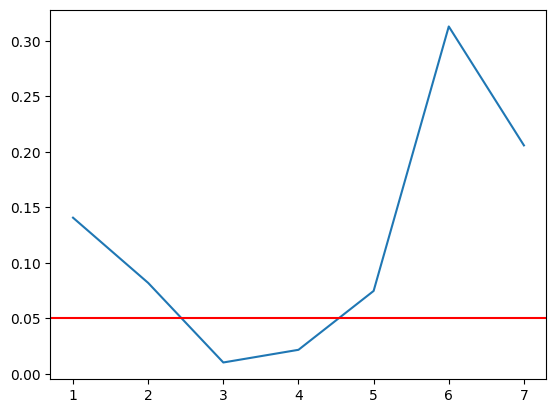

In [ ]:
plt.plot(df_fin2['date'] , df_fin2['p'])
plt.axhline(.05, color = 'red')
plt.show()

**Вывод**

Нельзя подсматривать, так как прокрас может появиться в начале/середине, но потом пропасть.

# Задача 4. Когорты в А/Б-тестах

В онлайн-ритейлере на протяжении двух месяцев проводился длинный эксперимент с целью поднятия среднего клиентского чека.

Рассчитай результаты А/Б-теста в целом, затем декомпозируй результаты по месяцам и оцени динамику чека.

На основании полученных результатов сделай вывод о том, следует ли внедрять воздействие В на $100\%$ выборки.

**Решение**

In [ ]:
df_aft = pd.read_csv('ab_cohort.csv')

df_aft['date_purchase'] = pd.to_datetime(df_aft['date_purchase'])
df_aft['month'] = df_aft['date_purchase'].dt.month

df_aft.head()

,date_purchase,group,amt_payment,month
0,2023-09-01,control,120,9
1,2023-09-01,control,120,9
2,2023-09-01,test,3771,9
3,2023-09-01,control,135,9
4,2023-09-01,control,3334,9


## Пункт 1

In [ ]:
m_all_a    =  df_aft[df_aft['group']=='control']['amt_payment'].mean()
m_all_b    =  df_aft[df_aft['group']=='test']['amt_payment'].mean()

############
df_sep     =  df_aft[df_aft['month']==9]
m_sep_a    =  df_sep[df_sep['group']=='control']['amt_payment'].mean()
m_sep_b    =  df_sep[df_sep['group']=='test']['amt_payment'].mean()

############
df_oct     =  df_aft[df_aft['month']==10]
m_oct_a    =  df_oct[df_oct['group']=='control']['amt_payment'].mean()
m_oct_b    =  df_oct[df_oct['group']=='test']['amt_payment'].mean()

############
df_nov     =  df_aft[df_aft['month']==11]
m_nov_a    =  df_nov[df_nov['group']=='control']['amt_payment'].mean()
m_nov_b    =  df_nov[df_nov['group']=='test']['amt_payment'].mean()

############
df_sep_осt =  df_aft[df_aft['month'].isin([9,10])]
m_sep_oct_a    =  df_sep_осt[df_sep_осt['group']=='control']['amt_payment'].mean()
m_sep_oct_b    =  df_sep_осt[df_sep_осt['group']=='test']['amt_payment'].mean()

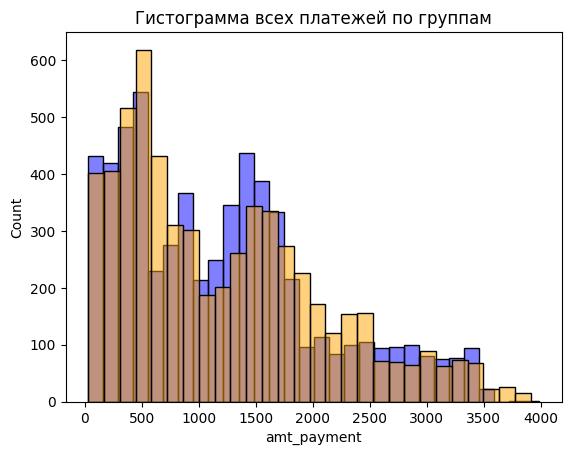

In [ ]:
sns.histplot(df_aft[df_aft['group']=='control']['amt_payment'], color='blue', alpha=0.5)
sns.histplot(df_aft[df_aft['group']=='test']['amt_payment']   , color='orange', alpha=0.5)
plt.title('Гистограмма всех платежей по группам')
plt.show()

In [ ]:
s_t, p_t = ttest_ind(df_aft[df_aft['group']=='control']['amt_payment'], df_aft[df_aft['group']=='test']['amt_payment'])

print(s_t)
print(p_t)

-0.4238028479137651
0.671717175051032


**Вывод**

Разницы между группами не обнаружено.

## Пункт 2

**Отдельно сентябрь.**

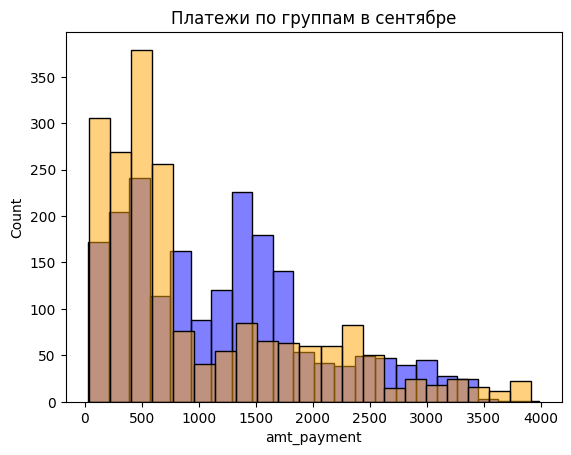

In [ ]:
sns.histplot(df_sep[df_sep['group']=='control']['amt_payment'], color='blue', alpha=0.5)
sns.histplot(df_sep[df_sep['group']=='test']['amt_payment']   , color='orange', alpha=0.5)
plt.title("Платежи по группам в сентябре")
plt.show()

In [ ]:
s_t_s, p_t_s = ttest_ind(df_sep[df_sep['group']=='control']['amt_payment'],df_sep[df_sep['group']=='test']['amt_payment'])

print(s_t_s)
print(p_t_s)

7.139024028590096
1.1111752068641052e-12


**Вывод**

Обнаружена статистически значимая разница.

Группа теста оказывается хуже контрольной.

**Отдельно октябрь.**

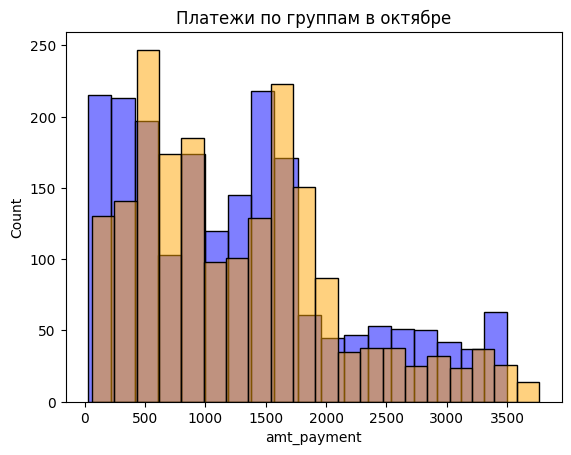

In [ ]:
sns.histplot(df_oct[df_oct['group']=='control']['amt_payment'], color='blue', alpha=0.5)
sns.histplot(df_oct[df_oct['group']=='test']['amt_payment']   , color='orange', alpha=0.5)
plt.title("Платежи по группам в октябре")
plt.show()

In [ ]:
s_t_o, p_t_o = ttest_ind(df_oct[df_oct['group']=='control']['amt_payment'],df_oct[df_oct['group']=='test']['amt_payment'])

print(s_t_o)
print(p_t_o)

-0.9079969708527332
0.3639353828226727


**Вывод**

Не обнаружена статистически значимая разница.

**Отдельно ноябрь.**

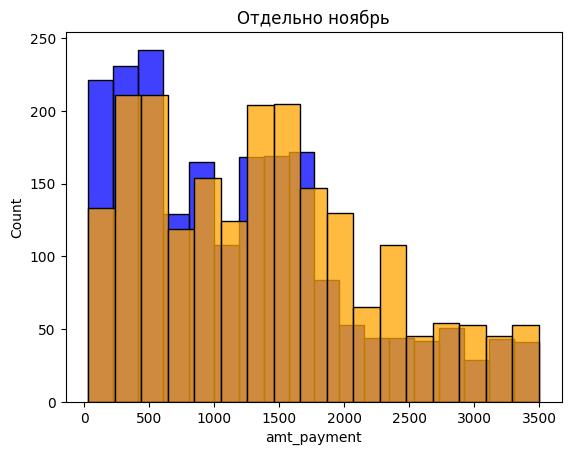

In [ ]:
sns.histplot(df_nov[df_nov['group']=='control']['amt_payment'], color='blue')
sns.histplot(df_nov[df_nov['group']=='test']['amt_payment']   , color='orange')
plt.title("Отдельно ноябрь")
plt.show()

In [ ]:
s_t_n, p_t_n = ttest_ind(df_nov[df_nov['group']=='control']['amt_payment'],df_nov[df_nov['group']=='test']['amt_payment'])

print(s_t_n)
print(p_t_n)

-6.8972630004415745
6.115314163664507e-12


**Вывод**

Обнаружена статистически значимая разница.

Но в этом месяце тестовая группа оказывается значимо выше контрольной.

## Пункт 3


**Сентябрь + октябрь.**


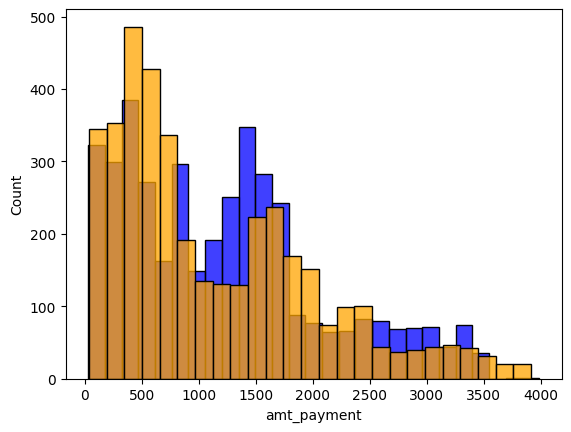

In [ ]:
sns.histplot(df_sep_осt[df_sep_осt['group']=='control']['amt_payment'], color='blue')
sns.histplot(df_sep_осt[df_sep_осt['group']=='test']['amt_payment']   , color='orange')

plt.show()

In [ ]:
s_t_so, p_t_so = ttest_ind(df_sep_осt[df_sep_осt['group']=='control']['amt_payment'],df_sep_осt[df_sep_осt['group']=='test']['amt_payment'])

print(s_t_so)
print(p_t_so)

4.446609183711302
8.842322132708862e-06


**Рассмотрим данные в динамике**

Рассмотрим накопленные и ненакопленные кривые средних чеков для каждой группы.

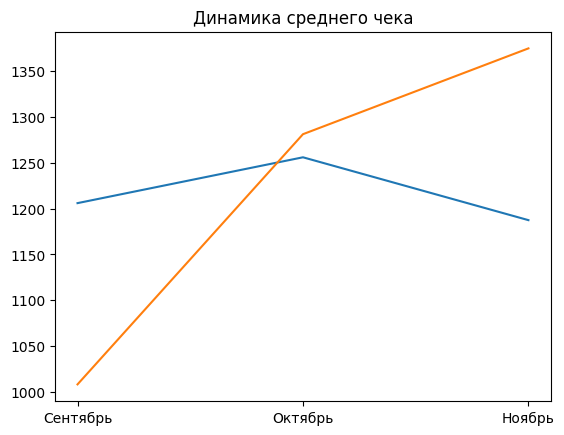

In [ ]:
xtitle = ["Сентябрь", "Октябрь", "Ноябрь"]
plt.plot(xtitle, [m_sep_a, m_oct_a, m_nov_a])
plt.plot(xtitle, [m_sep_b, m_oct_b, m_nov_b])
plt.title("Динамика среднего чека")
plt.show()

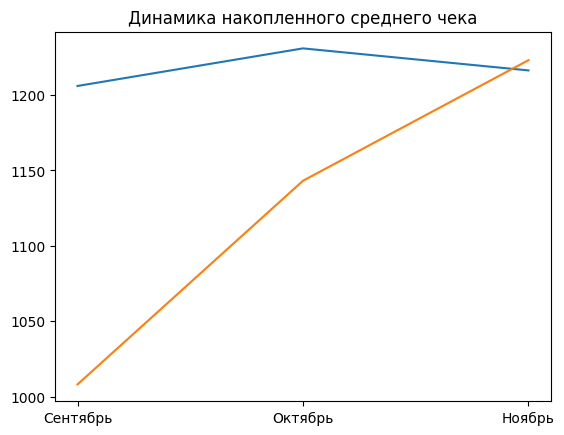

In [ ]:
plt.plot(xtitle, [m_sep_a, m_sep_oct_a, m_all_a])
plt.plot(xtitle, [m_sep_b, m_sep_oct_b, m_all_b])
plt.title("Динамика накопленного среднего чека")
plt.show()

**Вывод**

Бывают ситуации, когда эффект от воздействия В может проявиться не сразу. Важно изучать не только общий результат, но и смотреть на значения в динамике.

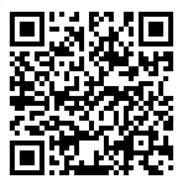